# Assignment 2 — Language Model Training
**Skill Nexis | Week 2: Creating a Small Language Model**

## Objective
Implement a character-level bigram language model. It learns which character is likely to follow the current character, records training and validation losses, and generates text before and after training.

This notebook covers the six tasks listed in the Week 2 assignment. Run cells in order. Keep `dataset.txt` in the same folder as this notebook.

## Task 1 — Prepare a text dataset
The dataset is a small original educational text written for this project and released under CC0 1.0 for reuse. It demonstrates the workflow; it is not large enough to produce polished prose.

In [2]:
from pathlib import Path
import csv
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
print("PyTorch version:", torch.__version__)

PyTorch version: 2.14.1+cpu


In [3]:
candidate_paths = [Path("dataset.txt"), Path("Assignment_2_Language_Model_Training") / "dataset.txt"]
DATASET_PATH = next((p for p in candidate_paths if p.exists()), None)
if DATASET_PATH is None:
    raise FileNotFoundError("dataset.txt was not found. Keep it beside this notebook or run from the project root.")
text = DATASET_PATH.read_text(encoding="utf-8").strip()
if len(text) < 100:
    raise ValueError("Dataset is unexpectedly short. Check dataset.txt.")
print("Dataset:", DATASET_PATH)
print("Character count:", len(text))
print("Word count:", len(text.split()))
print("\nPreview:\n", text[:300])

Dataset: dataset.txt
Character count: 1310
Word count: 233

Preview:
 The little bird sat beside the window.
Every morning the sun warmed the quiet garden.
A gentle wind moved through the green trees.
The bird watched children walking along the road.
Some children carried books and some carried flowers.
At noon the garden became bright and full of sound.
The bird sang


## Task 2 — Build a character vocabulary
Each unique character, including spaces and punctuation, receives an integer ID.

In [4]:
chars = sorted(set(text))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}
print("Vocabulary size:", vocab_size)
print("Characters:", repr("".join(chars)))

Vocabulary size: 36
Characters: '\n ,.AEINRSTWabcdefghiklmnopqrstuvwxy'


## Task 3 — Implement text encoding and decoding
`encode()` maps characters to IDs. `decode()` maps IDs back to characters. The round-trip test checks that the original text is recovered.

In [5]:
def encode(s: str) -> list[int]:
    return [stoi[ch] for ch in s]

def decode(ids: list[int]) -> str:
    return "".join(itos[int(i)] for i in ids)

encoded = encode(text)
decoded = decode(encoded)
assert decoded == text, "Encoding/decoding round-trip failed."
data = torch.tensor(encoded, dtype=torch.long)
print("Encoded tensor shape:", tuple(data.shape))
print("First 30 IDs:", encoded[:30])
print("Decoded first 100 characters:", repr(decode(encoded[:100])))
print("Round-trip test passed:", decoded == text)

Encoded tensor shape: (1310,)
First 30 IDs: [10, 19, 16, 1, 22, 20, 30, 30, 22, 16, 1, 13, 20, 28, 15, 1, 29, 12, 30, 1, 13, 16, 29, 20, 15, 16, 1, 30, 19, 16]
Decoded first 100 characters: 'The little bird sat beside the window.\nEvery morning the sun warmed the quiet garden.\nA gentle wind '
Round-trip test passed: True


## Task 4 — Create separate training and validation data
The first 90% of the sequence is used for training and the final 10% for validation. This preserves sequence order rather than mixing future characters into training.

In [7]:
split_index = int(0.90 * len(data))
train_data = data[:split_index]
val_data = data[split_index:]
print(f"Training characters: {len(train_data)} ({len(train_data)/len(data):.1%})")
print(f"Validation characters: {len(val_data)} ({len(val_data)/len(data):.1%})")
assert len(train_data) > 1 and len(val_data) > 1

Training characters: 1179 (90.0%)
Validation characters: 131 (10.0%)


## Task 5 — Train a bigram language model and record losses
The model predicts the next character using only the current character. A trainable table maps each current character to logits over possible next characters. Cross-entropy loss measures prediction error; lower values generally indicate better next-character prediction on the evaluated split.

In [8]:
device = torch.device("cpu")
BATCH_SIZE = 32
MAX_STEPS = 1200
EVAL_INTERVAL = 100
LEARNING_RATE = 0.03

def get_batch(split: str):
    source = train_data if split == "train" else val_data
    ix = torch.randint(len(source) - 1, (BATCH_SIZE,))
    x = torch.stack([source[i:i+1] for i in ix]).to(device)
    y = torch.stack([source[i+1:i+2] for i in ix]).to(device)
    return x, y

class BigramLanguageModel(nn.Module):
    def __init__(self, vocab_size: int):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size)

    def forward(self, idx, targets=None):
        logits = self.token_embedding_table(idx)
        loss = None
        if targets is not None:
            B, T, C = logits.shape
            loss = F.cross_entropy(logits.view(B*T, C), targets.view(B*T))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens: int, temperature: float = 1.0):
        for _ in range(max_new_tokens):
            logits, _ = self(idx)
            logits = logits[:, -1, :] / max(temperature, 1e-6)
            probs = F.softmax(logits, dim=-1)
            next_idx = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, next_idx), dim=1)
        return idx

model = BigramLanguageModel(vocab_size).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

BigramLanguageModel(
  (token_embedding_table): Embedding(36, 36)
)
Trainable parameters: 1296


In [9]:
@torch.no_grad()
def estimate_loss(eval_batches: int = 30):
    model.eval()
    results = {}
    for split in ("train", "val"):
        losses = torch.zeros(eval_batches)
        for k in range(eval_batches):
            xb, yb = get_batch(split)
            _, loss = model(xb, yb)
            losses[k] = loss.item()
        results[split] = losses.mean().item()
    model.train()
    return results

start_char = " " if " " in stoi else chars[0]
start_id = stoi[start_char]
before_ids = model.generate(torch.tensor([[start_id]], dtype=torch.long), 300)
before_training_sample = decode(before_ids[0].tolist())
print("SAMPLE BEFORE TRAINING\n")
print(before_training_sample)

SAMPLE BEFORE TRAINING

 ,cEht olI.rdyaEktm xh.etAo. oR
ro.ohWlAusStsSyynTrd,puyqtlg. olfWTTToRx rRRtddvlEkI.NwIdp
mfmcnqxuhc. oSSerNEcSylhNuhIT ,h
dpk.iqxc,.q.rio hfds
, fq bqbSAuhfhWTT
oShf

 to.etbS.pWTqwmwRxmfT osEpidkAolfawesgshfoWhmI rummy.b
ScvlnxeTr
m oaNbrxfewWvlkxhyp
nyaoiypmo,AW yNtsaRaxhfmlewsuhNAgnd
eNhgftswIxu


In [10]:
loss_history = []
for step in range(MAX_STEPS + 1):
    if step % EVAL_INTERVAL == 0 or step == MAX_STEPS:
        metrics = estimate_loss()
        loss_history.append({"step": step, "training_loss": metrics["train"], "validation_loss": metrics["val"]})
        print(f"step {step:4d} | training loss {metrics['train']:.4f} | validation loss {metrics['val']:.4f}")
    if step == MAX_STEPS:
        break
    xb, yb = get_batch("train")
    _, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

results_path = Path("training_results.csv")
with results_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=["step", "training_loss", "validation_loss"])
    writer.writeheader()
    writer.writerows(loss_history)
print("Loss history saved to:", results_path.resolve())

step    0 | training loss 4.1247 | validation loss 4.0111
step  100 | training loss 2.5218 | validation loss 2.7372
step  200 | training loss 2.1199 | validation loss 2.4044
step  300 | training loss 2.0703 | validation loss 2.3210
step  400 | training loss 2.0486 | validation loss 2.2734
step  500 | training loss 1.9760 | validation loss 2.2841
step  600 | training loss 1.9392 | validation loss 2.2651
step  700 | training loss 1.9300 | validation loss 2.2180
step  800 | training loss 2.0299 | validation loss 2.2631
step  900 | training loss 1.9763 | validation loss 2.2676
step 1000 | training loss 1.9942 | validation loss 2.2964
step 1100 | training loss 1.9861 | validation loss 2.3449
step 1200 | training loss 1.9762 | validation loss 2.2604
Loss history saved to: C:\Users\YASH D JAIN\OneDrive\Desktop\skill-nexis-llm-development-week-2\Assignment_2_Language_Model_Training\training_results.csv


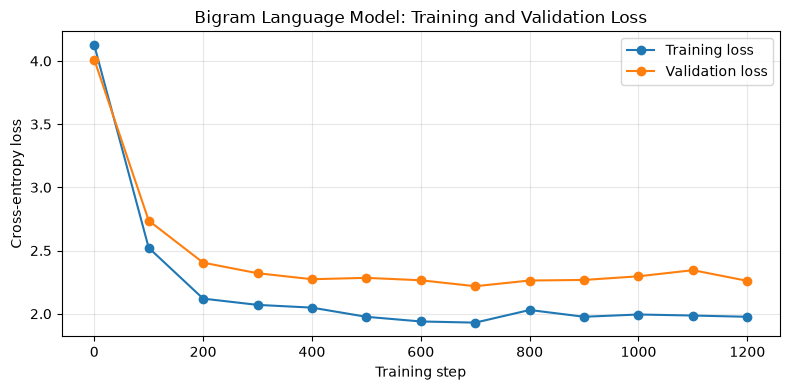

In [11]:
steps = [row["step"] for row in loss_history]
train_losses = [row["training_loss"] for row in loss_history]
val_losses = [row["validation_loss"] for row in loss_history]
plt.figure(figsize=(8, 4))
plt.plot(steps, train_losses, marker="o", label="Training loss")
plt.plot(steps, val_losses, marker="o", label="Validation loss")
plt.xlabel("Training step")
plt.ylabel("Cross-entropy loss")
plt.title("Bigram Language Model: Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Task 6 — Compare generated samples before and after training
Generation is stochastic, so the exact output can vary between runs. Compare the visible patterns rather than assuming the trained sample must be coherent.

In [12]:
after_ids = model.generate(torch.tensor([[start_id]], dtype=torch.long), 300)
after_training_sample = decode(after_ids[0].tolist())
print("SAMPLE BEFORE TRAINING\n")
print(before_training_sample)
print("\n" + "=" * 60 + "\n")
print("SAMPLE AFTER TRAINING\n")
print(after_training_sample)

SAMPLE BEFORE TRAINING

 ,cEht olI.rdyaEktm xh.etAo. oR
ro.ohWlAusStsSyynTrd,puyqtlg. olfWTTToRx rRRtddvlEkI.NwIdp
mfmcnqxuhc. oSSerNEcSylhNuhIT ,h
dpk.iqxc,.q.rio hfds
, fq bqbSAuhfhWTT
oShf

 to.etbS.pWTqwmwRxmfT osEpidkAolfawesgshfoWhmI rummy.b
ScvlnxeTr
m oaNbrxfewWvlkxhyp
nyaoiypmo,AW yNtsaRaxhfmlewsuhNAgnd
eNhgftswIxu


SAMPLE AFTER TRAINING

 areded casmamoler ngan at mo the skyoug fo s.
Whe ganethie nd tcars.
Th ry.
Eved.
So s.
In stond gh ly sthene oun drd rnd arst orexthe trrieshe stlese cad yofumoowndrathen sthtan tud brren atheg be.
Rard ward the l are sulle bearde trde tl llare ced chee smend.
Afld t chestun twe w spewandrd flly on


In [13]:
first = loss_history[0]
last = loss_history[-1]
print("Initial training loss:", round(first["training_loss"], 4))
print("Final training loss:", round(last["training_loss"], 4))
print("Initial validation loss:", round(first["validation_loss"], 4))
print("Final validation loss:", round(last["validation_loss"], 4))
print("Training loss decreased:", last["training_loss"] < first["training_loss"])
print("Validation loss decreased:", last["validation_loss"] < first["validation_loss"])
print("\nInterpretation:")
print("Use the displayed losses and samples to describe what happened. Do not claim improvement unless the recorded values support it. A bigram model sees only the immediately previous character and may produce incoherent text.")

Initial training loss: 4.1247
Final training loss: 1.9762
Initial validation loss: 4.0111
Final validation loss: 2.2604
Training loss decreased: True
Validation loss decreased: True

Interpretation:
Use the displayed losses and samples to describe what happened. Do not claim improvement unless the recorded values support it. A bigram model sees only the immediately previous character and may produce incoherent text.


## Conclusion
This notebook demonstrates dataset preparation, character vocabulary construction, encoding/decoding, a sequential train/validation split, bigram model training, loss recording, and a comparison of generated text before and after training.

**Limitation:** a character-level bigram model conditions on only one previous character. It is a teaching model, not a modern large language model, and its output may be incoherent.